# Part 2 of 6: Custom CNN & ResNet18: Models, Training & Tuning

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 7–9: the custom CNN and ResNet18, the training engine, hyperparameter tuning, ablations and the selection of both models on the validation set. The ViT is trained in notebook 03.

The notebooks run in order: `01_data` → `02_cnn_resnet` → `03_vit` → `04_test_evaluation` → `05_robustness` → `06_discussion`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plantdisease.config import SEEDS, out_path
from plantdisease.data import prepare
from plantdisease.evaluate import mean_sd
from plantdisease.experiments import (
    ALL_CONFIGS,
    TUNING_SEED,
    cnn_configs,
    resnet_configs,
    save_selected,
)
from plantdisease.models import build_model, count_params
from plantdisease.plots import finish
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | notebook 03 |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone is unfrozen and trained with a smaller learning rate. The models are defined in `plantdisease/models.py`.

In [2]:
for arch in ["cnn", "se_cnn"]:
    print(
        f"{arch:8s} parameters: {count_params(build_model({'arch': arch, 'dropout': 0.3})):,}"
    )

cnn      parameters: 389,924
se_cnn   parameters: 412,224


## 8. Training Engine

`run(name, cfg, seed, data)` (`plantdisease/train.py`) trains one configuration with one seed:
- **AdamW** (Adam with decoupled weight decay), optionally with a **cosine learning-rate schedule** stepped every batch;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning; in the second stage the head and the backbone can have different learning rates (used by the ViT);
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **early stopping**: training stops when the validation macro-F1 has not improved for `patience` epochs (`CFG["patience"]`: 10 for the custom CNN, 5 for ResNet18 and the ViT). The count starts with the last training stage, so a pre-trained model always fine-tunes for at least `patience` epochs. A cosine schedule keeps its full length, so a run that stops early ends before its learning rate reaches zero;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (ties keep the earlier epoch). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained;
- **training cost**: per epoch the training time without validation (measured after the GPU has finished), the number of trainable parameters, and the peak memory of the run (exact on CUDA, sampled on Apple MPS).

The test set is never touched here.

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 and 9.2 use training seed 62 and are compared by the **best validation macro-F1**. Section 9.3 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

All configurations are defined in `plantdisease/experiments.py`.

In [3]:
histories = {
    name: run(name, cfg, TUNING_SEED, data) for name, cfg in cnn_configs.items()
}


===== SE-CNN (full recipe) (seed 62) =====
Epoch 1/50 [finetune] | train loss 0.4799 acc 0.8243 | val loss 0.2479 acc 0.9029 macro-F1 0.9048 | 25s
Epoch 2/50 [finetune] | train loss 0.2698 acc 0.9006 | val loss 0.2348 acc 0.9157 macro-F1 0.9178 | 25s
Epoch 3/50 [finetune] | train loss 0.2162 acc 0.9160 | val loss 0.4265 acc 0.8129 macro-F1 0.8196 | 24s
Epoch 4/50 [finetune] | train loss 0.1641 acc 0.9376 | val loss 0.0808 acc 0.9786 macro-F1 0.9783 | 25s
Epoch 5/50 [finetune] | train loss 0.1453 acc 0.9497 | val loss 0.0506 acc 0.9900 macro-F1 0.9893 | 24s
Epoch 6/50 [finetune] | train loss 0.1160 acc 0.9558 | val loss 0.0889 acc 0.9729 macro-F1 0.9724 | 26s
Epoch 7/50 [finetune] | train loss 0.0938 acc 0.9645 | val loss 0.0531 acc 0.9843 macro-F1 0.9843 | 29s
Epoch 8/50 [finetune] | train loss 0.0973 acc 0.9642 | val loss 0.0752 acc 0.9686 macro-F1 0.9672 | 24s
Epoch 9/50 [finetune] | train loss 0.0837 acc 0.9707 | val loss 0.0880 acc 0.9686 macro-F1 0.9701 | 23s
Epoch 10/50 [finetun

In [4]:
histories.update(
    {name: run(name, cfg, TUNING_SEED, data) for name, cfg in resnet_configs.items()}
)


===== ResNet18 frozen backbone (seed 62) =====
Epoch 1/16 [head] | train loss 0.7207 acc 0.7461 | val loss 0.3489 acc 0.9129 macro-F1 0.9110 | 10s
Epoch 2/16 [head] | train loss 0.3264 acc 0.9018 | val loss 0.2195 acc 0.9429 macro-F1 0.9408 | 9s
Epoch 3/16 [head] | train loss 0.2519 acc 0.9206 | val loss 0.1772 acc 0.9457 macro-F1 0.9416 | 10s
Epoch 4/16 [head] | train loss 0.2172 acc 0.9299 | val loss 0.1602 acc 0.9571 macro-F1 0.9551 | 10s
Epoch 5/16 [head] | train loss 0.2000 acc 0.9327 | val loss 0.1401 acc 0.9629 macro-F1 0.9612 | 9s
Epoch 6/16 [head] | train loss 0.1850 acc 0.9364 | val loss 0.1414 acc 0.9557 macro-F1 0.9533 | 10s
Epoch 7/16 [head] | train loss 0.1679 acc 0.9469 | val loss 0.1180 acc 0.9657 macro-F1 0.9640 | 9s
Epoch 8/16 [head] | train loss 0.1688 acc 0.9398 | val loss 0.1340 acc 0.9557 macro-F1 0.9541 | 9s
Epoch 9/16 [head] | train loss 0.1465 acc 0.9494 | val loss 0.1109 acc 0.9657 macro-F1 0.9648 | 9s
Epoch 10/16 [head] | train loss 0.1425 acc 0.9500 | val l

In [5]:
def summarize(name):
    h, cfg = histories[name], ALL_CONFIGS[name]
    best = int(np.argmax(h["val_f1"]))
    return {
        "run": name,
        "arch": cfg["arch"],
        "lr": cfg["lr"],
        "batch": cfg["batch_size"],
        "dropout": cfg["dropout"],
        "augment": cfg["augment"],
        "class_w": cfg["class_weights"],
        "schedule": cfg["scheduler"],
        "best_epoch": best + 1,
        "val_acc": h["val_acc"][best],
        "val_macro_f1": h["val_f1"][best],
        "train_s_per_epoch": np.mean(h["train_time"]),
    }


tuning = pd.DataFrame([summarize(n) for n in histories]).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,5,0.9900,0.9893,23.3140
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,10,0.9957,0.9956,22.6939
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,12,0.9943,0.9942,27.8539
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,19,0.9986,0.9987,15.6362
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,17,0.9986,0.9987,21.4563
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,22,1.0000,1.0000,22.9254
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,16,0.9986,0.9983,22.9301
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,5,0.9857,0.9860,22.7351
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,7,0.9971,0.9970,22.8617


### 9.3 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 62) are therefore repeated with all training seeds. The **final models are chosen by the mean validation macro-F1 over the seeds**, shown with the standard deviation over the seeds. The test set is not used here.

In [6]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": cnn_configs, "resnet18": resnet_configs}
rows = []
for family, configs in families.items():
    top = tuning.loc[list(configs), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = [max(run(name, configs[name], seed, data)["val_f1"]) for seed in SEEDS]
        rows.append(
            {
                "family": family,
                "run": name,
                f"val macro-F1 (seed {TUNING_SEED})": tuning.at[name, "val_macro_f1"],
                "mean over seeds": np.mean(scores),
                "mean ± sd": mean_sd(scores),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

for family in families:
    best = multi_seed.loc[multi_seed.family == family, "mean over seeds"].idxmax()
    save_selected(family, best)  # OUT_DIR/final_models.json, read by notebooks 04-06
    print(f"Selected {family}: {best}")
multi_seed.round(4)

Loaded finished run: SE-CNN no dropout (seed 62)

===== SE-CNN no dropout (seed 63) =====
Epoch 1/50 [finetune] | train loss 0.4946 acc 0.8162 | val loss 0.3259 acc 0.8829 macro-F1 0.8825 | 24s
Epoch 2/50 [finetune] | train loss 0.2581 acc 0.9024 | val loss 0.1808 acc 0.9343 macro-F1 0.9364 | 25s
Epoch 3/50 [finetune] | train loss 0.2008 acc 0.9265 | val loss 0.1136 acc 0.9714 macro-F1 0.9725 | 26s
Epoch 4/50 [finetune] | train loss 0.1474 acc 0.9472 | val loss 0.0967 acc 0.9786 macro-F1 0.9796 | 25s
Epoch 5/50 [finetune] | train loss 0.1145 acc 0.9602 | val loss 0.0668 acc 0.9800 macro-F1 0.9784 | 25s
Epoch 6/50 [finetune] | train loss 0.1138 acc 0.9555 | val loss 0.0403 acc 0.9900 macro-F1 0.9890 | 25s
Epoch 7/50 [finetune] | train loss 0.0862 acc 0.9722 | val loss 0.2702 acc 0.9171 macro-F1 0.9151 | 24s
Epoch 8/50 [finetune] | train loss 0.0877 acc 0.9663 | val loss 0.0191 acc 0.9943 macro-F1 0.9936 | 24s
Epoch 9/50 [finetune] | train loss 0.0783 acc 0.9731 | val loss 0.1210 acc 0.9

,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
run,,,,
SE-CNN no dropout,cnn,1.0000,0.9989,0.9989 ± 0.0010
CNN (no attention),cnn,0.9987,0.9930,0.9930 ± 0.0082
SE-CNN no augmentation,cnn,0.9987,0.9965,0.9965 ± 0.0024
"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.0000,1.0000,1.0000 ± 0.0000
"ResNet18 two-stage + cosine, lr=3e-4",resnet18,1.0000,1.0000,1.0000 ± 0.0000


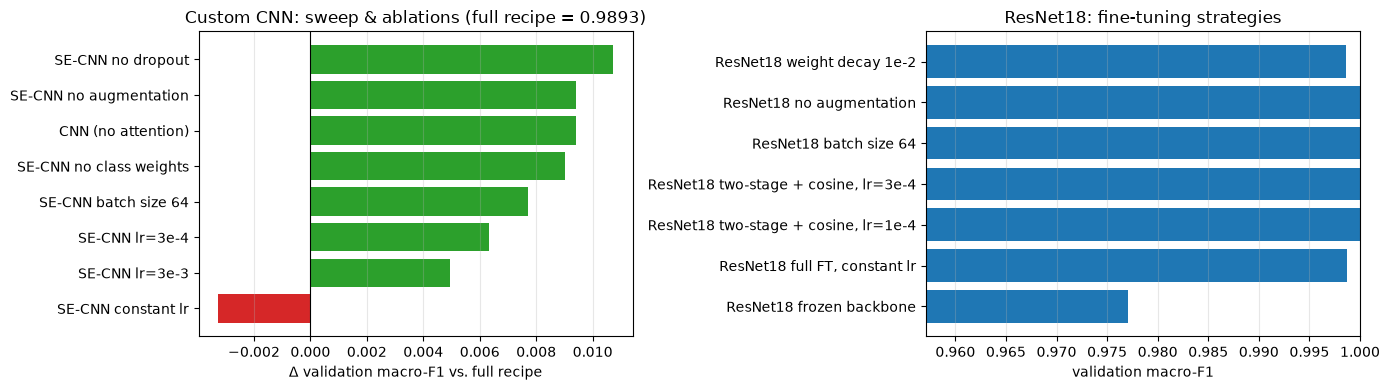

In [7]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(cnn_configs)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(resnet_configs), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("ResNet18: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

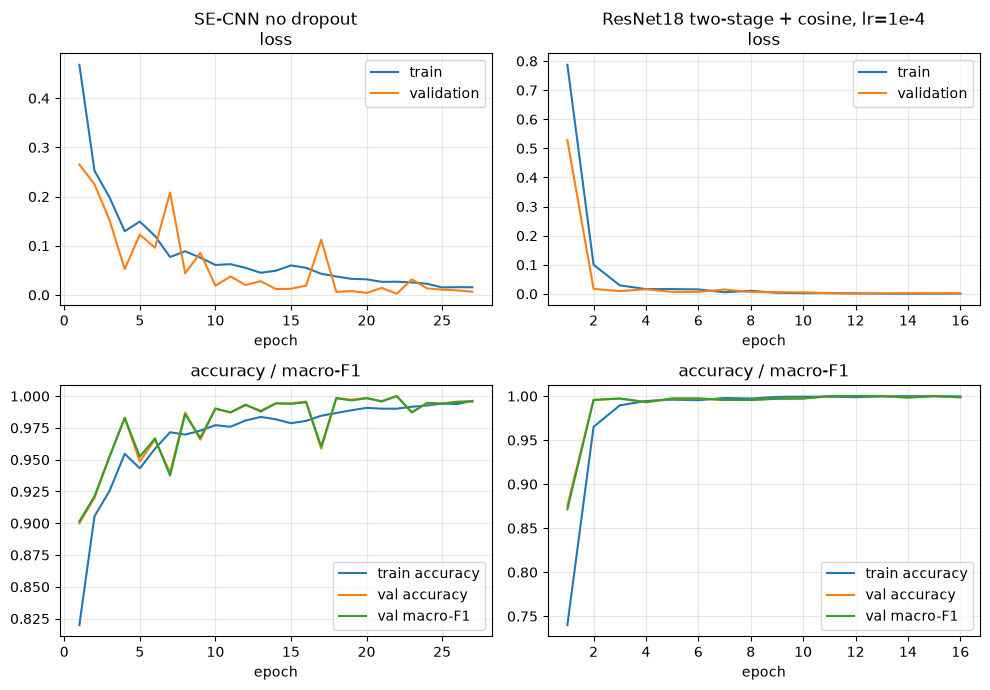

In [8]:
# Learning curves of the selected models (tuning seed)
selected = [
    multi_seed.loc[multi_seed.family == f, "mean over seeds"].idxmax() for f in families
]
fig, axes = plt.subplots(2, len(selected), figsize=(5 * len(selected), 7))
for col, name in enumerate(selected):
    h = histories[name]
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[0, col].plot(epochs, h["train_loss"], label="train")
    axes[0, col].plot(epochs, h["val_loss"], label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h["train_acc"], label="train accuracy")
    axes[1, col].plot(epochs, h["val_acc"], label="val accuracy")
    axes[1, col].plot(epochs, h["val_f1"], label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")